In [1]:
# Con esto instalamos directamente en el kernel que el notebook tiene abierto ahora
import sys
!{sys.executable} -m pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Defaulting to user installation because normal site-packages is not writeable


Leo el archivo e imprimo las primeras lineas del archivo

In [2]:
df_restaurantes = pd.read_csv('base_datos_restaurantes_USA_v2.csv')
df_restaurantes.head()

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,NaN,Efectivo,6425
1,9446112038,Samantha,Soto,40.0,Femenino,Denver,Medio,2,44.92,Sí,Sí,Mariscos,No,881-476-1426,NaN,Efectivo,2374
2,3098363243,Terry,Adams,62.0,Femenino,Denver,Bajo,2,9.24,Sí,Sí,Vegetariano,No,NaN,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41.0,Masculino,Boston,Alto,5,30.74,Sí,Sí,Carnes,Sí,NaN,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49.0,Femenino,San Diego,Bajo,0,0.00,No,No,Carnes,No,243.248.8919,glassgary@example.org,Tarjeta,1350


### 1. Exploración y Limpieza de Datos
Después de cargar la base, le di una mirada rápida para ver con qué me encontraba. Noté que hay algunos errores de carga bastante evidentes (como clientes con -5 años o 300 años) y algunos datos faltantes. 

Para dejar la base lista, tomé estas decisiones:
* Borré los duplicados exactos.
* Filtré las edades para quedarme solo con valores lógicos (entre 18 y 100 años). Esto de paso limpió los nulos que había en esa columna.
* Como había clientes que no declararon sus preferencias alimenticias, les puse "Sin especificar" para no borrarlos y perder el resto de su info.
* Con los nulos en el promedio de gasto, usé la mediana para rellenarlos y no alterar el promedio general.

In [3]:
# EXPLORACIÓN INICIAL DEL DATASET
print("INFORMACIÓN GENERAL")
df_restaurantes.info()
print("\nESTADÍSTICAS DESCRIPTIVAS")
print(df_restaurantes.describe())
print("\nVALORES NULOS")
print(df_restaurantes.isnull().sum())
print("\nDUPLICADOS")
print(df_restaurantes.duplicated().sum())
# Elimino filas duplicadas por las dudas
df_restaurantes.drop_duplicates(inplace=True)
# Filtro edades ilógicas (esto también vuela los nulos en 'edad')
df_restaurantes = df_restaurantes[(df_restaurantes['edad'] >= 18) & (df_restaurantes['edad'] <= 100)].copy()
# Relleno los datos faltantes
df_restaurantes['preferencias_alimenticias'] = df_restaurantes['preferencias_alimenticias'].fillna('Sin especificar')
df_restaurantes['promedio_gasto_comida'] = df_restaurantes['promedio_gasto_comida'].fillna(df_restaurantes['promedio_gasto_comida'].median())
# Chequeo rápido para confirmar que ya no quedan nulos importantes
print("Nulos restantes:\n", df_restaurantes[['edad', 'preferencias_alimenticias', 'promedio_gasto_comida']].isnull().sum())

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  int64  
 1   nombre                     30000 non-null  object 
 2   apellido                   30000 non-null  object 
 3   edad                       29899 non-null  float64
 4   genero                     30000 non-null  object 
 5   ciudad_residencia          30000 non-null  object 
 6   estrato_socioeconomico     30000 non-null  object 
 7   frecuencia_visita          30000 non-null  int64  
 8   promedio_gasto_comida      29855 non-null  float64
 9   ocio                       30000 non-null  object 
 10  consume_licor              30000 non-null  object 
 11  preferencias_alimenticias  28597 non-null  object 
 12  membresia_premium          30000 non-null  object 
 13  telefono_contacto         

### 2. Selección de la Ciudad
Como el proyecto pide enfocarnos en una sola ciudad, me fijé cuál es la que tiene más movimiento. Resulta que Chicago lidera cómoda, así que filtré la base para quedarme únicamente con esos clientes y asegurar que el análisis sea bien representativo.

In [4]:
# Miramos cuáles son las ciudades con más clientes
print("Top 5 ciudades con más clientes:")
print(df_restaurantes['ciudad_residencia'].value_counts().head(5))
# Elegimos Chicago por ser la que tiene más datos
ciudad_elegida = 'Chicago' 
df_final = df_restaurantes[df_restaurantes['ciudad_residencia'] == ciudad_elegida].copy()
print(f"\nListo. Base filtrada. Nos quedamos con {df_final.shape[0]} clientes de {ciudad_elegida}.")

Top 5 ciudades con más clientes:
ciudad_residencia
Chicago      5332
NYC          4717
Miami        3150
San Diego    3047
Dallas       2569
Name: count, dtype: int64

Listo. Base filtrada. Nos quedamos con 5332 clientes de Chicago.


### 3. Conociendo a los clientes de Chicago
Ahora que ya tenemos nuestra base enfocada en Chicago, armé unas tablas rápidas para entender bien el perfil de estos clientes. Quería ver cómo se reparten por género, qué tipo de comida prefieren y si son de consumir alcohol. Esto nos va a dar la pauta de por dónde encarar las campañas.

In [5]:
# 1. Distribución por Género
print("--- Clientes por Género ---")
tabla_genero = df_final['genero'].value_counts()
print(tabla_genero)
# 2. Preferencias Alimenticias
print("\n--- Preferencias Alimenticias ---")
tabla_comida = df_final['preferencias_alimenticias'].value_counts()
print(tabla_comida)
# 3. Consumo de Licor
print("\n--- Consumo de Licor ---")
tabla_licor = df_final['consume_licor'].value_counts()
print(tabla_licor)
# 4. Estrato Socioeconómico (Un extra útil para marketing)
print("\n--- Nivel Socioeconómico ---")
tabla_estrato = df_final['estrato_socioeconomico'].value_counts()
print(tabla_estrato)

--- Clientes por Género ---
genero
Masculino    2683
Femenino     2649
Name: count, dtype: int64

--- Preferencias Alimenticias ---
preferencias_alimenticias
Carnes             1578
Vegetariano        1114
Mariscos            691
Otro                585
Vegano              560
Pescado             538
Sin especificar     266
Name: count, dtype: int64

--- Consumo de Licor ---
consume_licor
Sí    3348
No    1984
Name: count, dtype: int64

--- Nivel Socioeconómico ---
estrato_socioeconomico
Medio       1776
Alto        1502
Bajo        1135
Muy Alto     919
Name: count, dtype: int64


Carga de Datos y Preparación

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Le damos un estilo profesional a los gráficos con Seaborn
sns.set_theme(style="whitegrid")
# 1. Cargamos tu base de datos exacta
df_clientes = pd.read_csv('base_datos_restaurantes_USA_v2.csv')
# 2. Creamos la columna 'gasto_mensual' que nos piden en el PI 3
# Lógica de negocio: Gasto Mensual = (Frecuencia de visita) * (Promedio de gasto por comida)
df_clientes['gasto_mensual'] = df_clientes['frecuencia_visita'] * df_clientes['promedio_gasto_comida']
print(f"Base de datos cargada exitosamente con {len(df_clientes)} clientes.")
print("Columna 'gasto_mensual' calculada y lista para el análisis.")

Base de datos cargada exitosamente con 30000 clientes.
Columna 'gasto_mensual' calculada y lista para el análisis.


1. Distribución Demográfica de los Clientes
En esta primera sección analizamos cómo se distribuye nuestra base de clientes a lo largo de las distintas ciudades. Esto nos permite identificar rápidamente nuestros mercados con mayor volumen de personas.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Le damos un estilo a los gráficos con Seaborn
sns.set_theme(style="whitegrid")
# 1. Cargamos tu base de datos exacta
df_clientes = pd.read_csv('base_datos_restaurantes_USA_v2.csv')
# 2. Creamos la columna 'gasto_mensual' que nos piden en el PI 3
# Lógica de negocio: Gasto Mensual = (Frecuencia de visita) * (Promedio de gasto por comida)
df_clientes['gasto_mensual'] = df_clientes['frecuencia_visita'] * df_clientes['promedio_gasto_comida']
print(f"Base de datos cargada exitosamente con {len(df_clientes)} clientes.")
print("Columna 'gasto_mensual' calculada y lista para el análisis.")

Base de datos cargada exitosamente con 30000 clientes.
Columna 'gasto_mensual' calculada y lista para el análisis.


1. Distribución Demográfica de los Clientes
En esta primera sección analizamos cómo se distribuye nuestra base de clientes a lo largo de las distintas ciudades. Esto nos permite identificar rápidamente nuestros mercados con mayor volumen de personas.

C:\Users\crist\AppData\Local\Temp\ipykernel_10916\3305736101.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_clientes, x='ciudad_residencia',


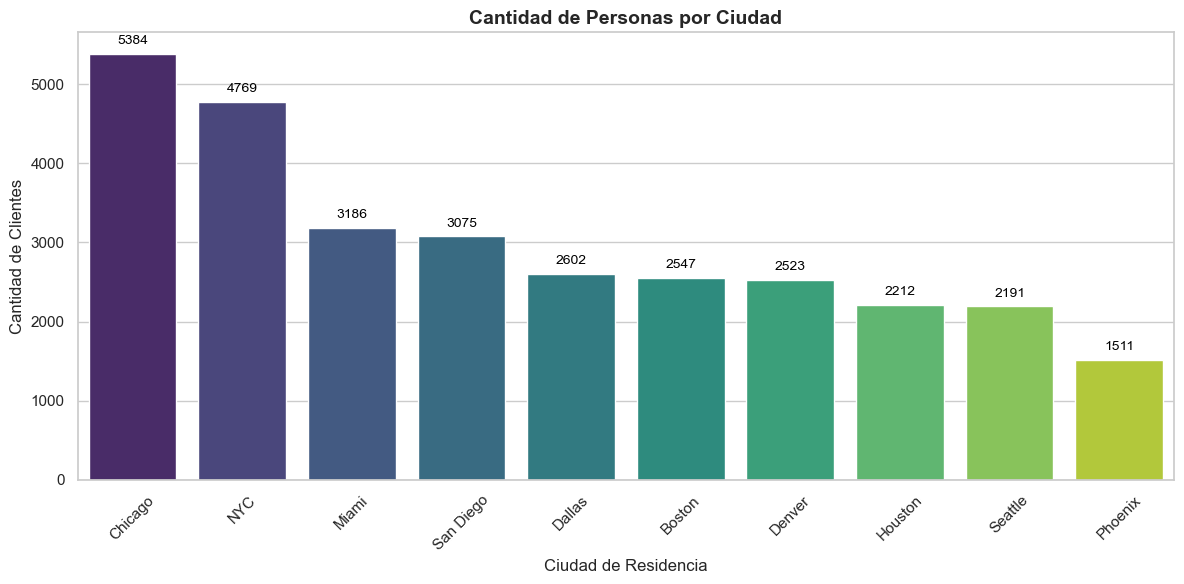

In [8]:
# --- PI 1: PERSONAS POR CIUDAD ---
plt.figure(figsize=(12, 6))
# Usamos countplot para contar cuántos clientes hay en cada ciudad
ax = sns.countplot(data=df_clientes, x='ciudad_residencia', 
                   order=df_clientes['ciudad_residencia'].value_counts().index, palette='viridis')
plt.title('Cantidad de Personas por Ciudad', fontsize=14, fontweight='bold')
plt.xlabel('Ciudad de Residencia', fontsize=12)
plt.ylabel('Cantidad de Clientes', fontsize=12)
plt.xticks(rotation=45) 
# Bucle para poner el valor exacto arriba de cada barra (queda muy pro)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 5), 
                textcoords='offset points')

plt.tight_layout()
plt.show()

2. Perfil Socioeconómico
A continuación, presentamos la distribución de nuestros clientes según su estrato socioeconómico. Conocer este perfil es indispensable para alinear la oferta gastronómica y las estrategias de precios.

In [9]:
# --- PI 2: DISTRIBUCIÓN POR ESTRATO ---

print("--- Distribución de Personas por Estrato Socioeconómico ---")

# Calculamos cantidades absolutas y porcentajes
conteo_estratos = df_clientes['estrato_socioeconomico'].value_counts()
porcentaje_estratos = df_clientes['estrato_socioeconomico'].value_counts(normalize=True) * 100

# Armamos un DataFrame prolijo para mostrarlo como tabla
df_estratos = pd.DataFrame({
    'Cantidad de Personas': conteo_estratos,
    'Porcentaje (%)': porcentaje_estratos.round(2)
})

display(df_estratos)

--- Distribución de Personas por Estrato Socioeconómico ---


,Cantidad de Personas,Porcentaje (%)
estrato_socioeconomico,,
Medio,9325,31.08
Alto,9038,30.13
Bajo,6161,20.54
Muy Alto,5476,18.25


3. Análisis de Gastos y Hábitos de Consumo
Analizamos el comportamiento financiero de los clientes respondiendo a tres ejes clave:

Ciudades con mayor volumen de gasto mensual promedio.

Relación entre la frecuencia de visitas y el gasto por comida, segmentado por estrato.

Correlación general entre ingresos mensuales y el gasto mensual estimado en restaurantes

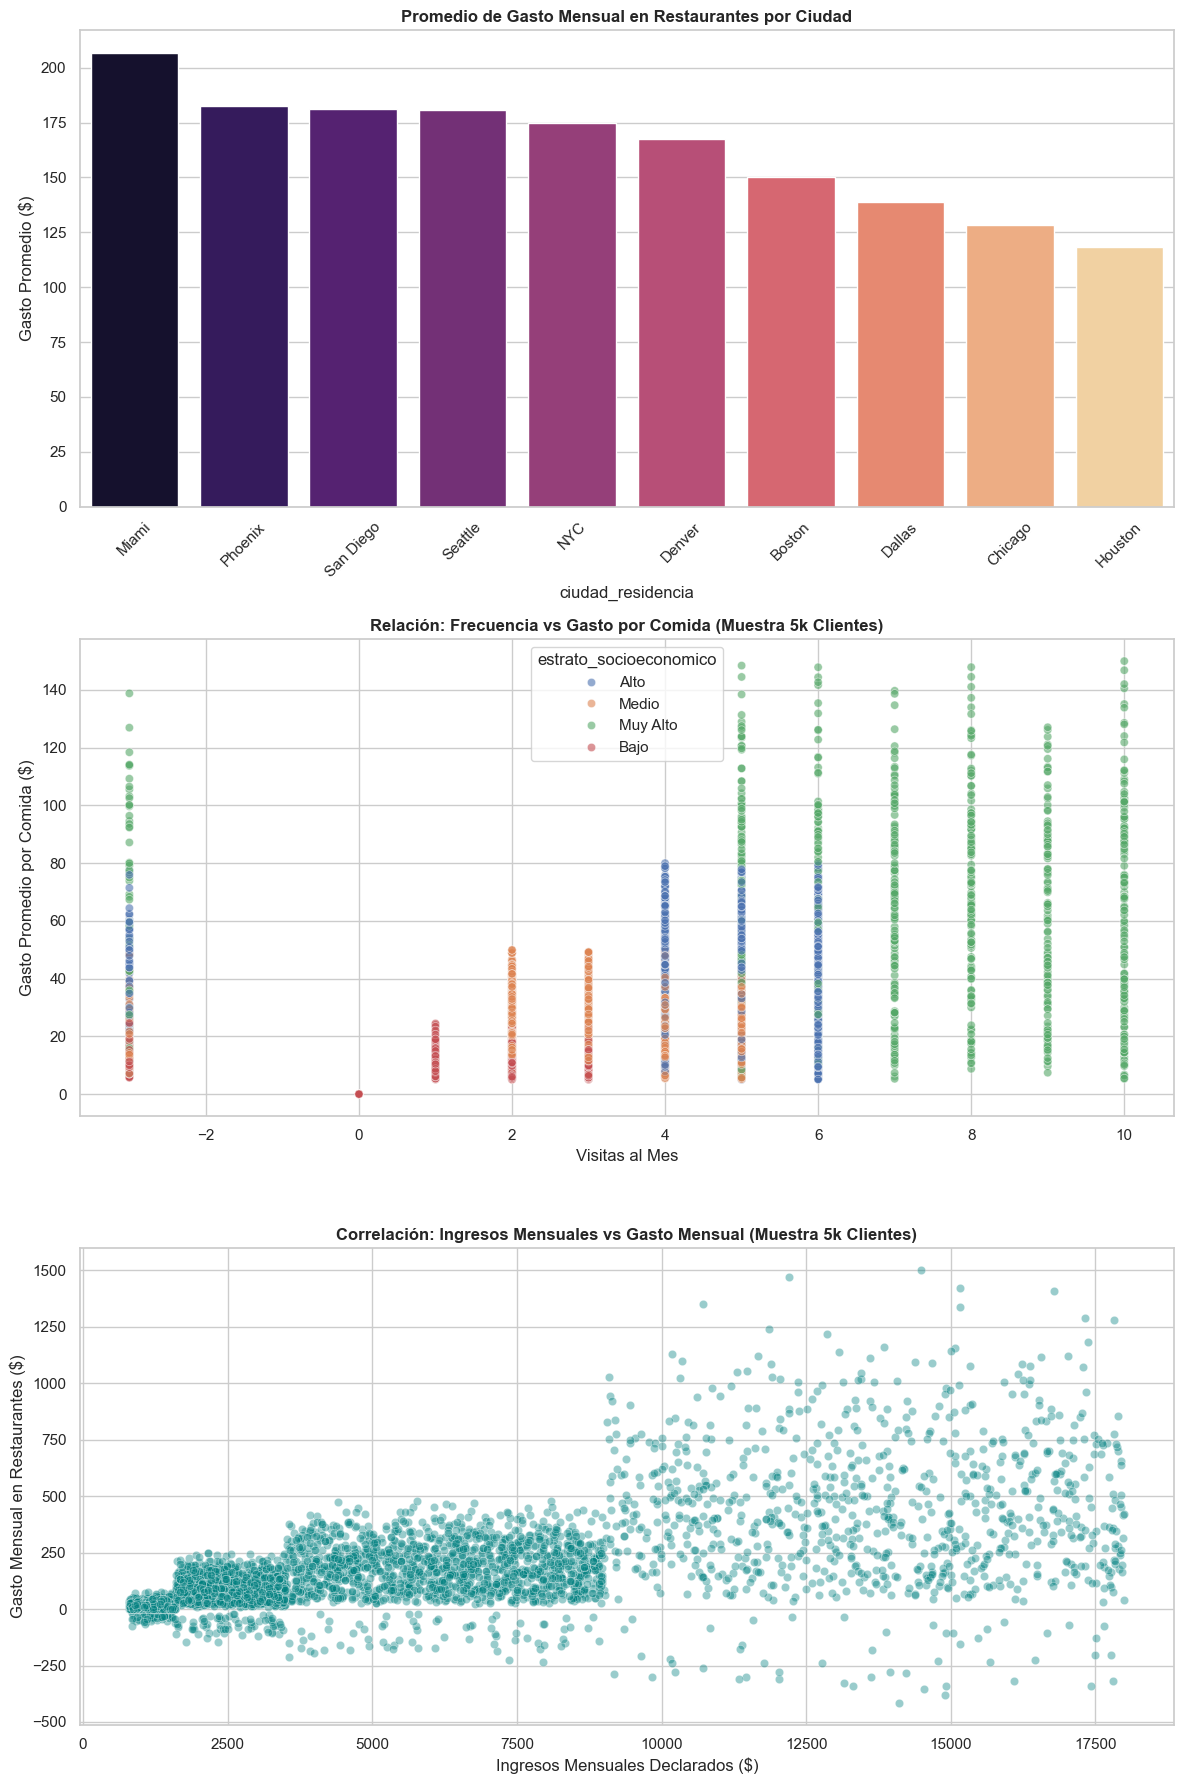

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Volvemos a cargar la base por si se borró de la memoria al frenar
df_clientes = pd.read_csv('base_datos_restaurantes_USA_v2.csv')
df_clientes['gasto_mensual'] = df_clientes['frecuencia_visita'] * df_clientes['promedio_gasto_comida']

# --- PI 3: GRÁFICOS FINANCIEROS 
fig, axes = plt.subplots(3, 1, figsize=(12, 18))

# Gráfico 1: Ciudades
gasto_ciudad = df_clientes.groupby('ciudad_residencia')['gasto_mensual'].mean().sort_values(ascending=False)
# (Le agregué hue y legend=False por si tenés una versión muy nueva de Seaborn que tira error de paleta)
sns.barplot(x=gasto_ciudad.index, y=gasto_ciudad.values, ax=axes[0], palette='magma', hue=gasto_ciudad.index, legend=False)
axes[0].set_title('Promedio de Gasto Mensual en Restaurantes por Ciudad', fontweight='bold')
axes[0].set_ylabel('Gasto Promedio ($)')
axes[0].tick_params(axis='x', rotation=45)

# ---  Tomamos una muestra de 5000 clientes al azar para que sea instantáneo ---
df_muestra = df_clientes.sample(n=5000, random_state=42)

# Gráfico 2: Frecuencia vs Gasto (Usando la muestra)
sns.scatterplot(data=df_muestra, x='frecuencia_visita', y='promedio_gasto_comida', 
                hue='estrato_socioeconomico', palette='deep', alpha=0.6, ax=axes[1])
axes[1].set_title('Relación: Frecuencia vs Gasto por Comida (Muestra 5k Clientes)', fontweight='bold')
axes[1].set_xlabel('Visitas al Mes')
axes[1].set_ylabel('Gasto Promedio por Comida ($)')

# Gráfico 3: Ingresos vs Gasto (Usando la muestra)
sns.scatterplot(data=df_muestra, x='ingresos_mensuales', y='gasto_mensual', 
                color='teal', alpha=0.4, ax=axes[2])
axes[2].set_title('Correlación: Ingresos Mensuales vs Gasto Mensual (Muestra 5k Clientes)', fontweight='bold')
axes[2].set_xlabel('Ingresos Mensuales Declarados ($)')
axes[2].set_ylabel('Gasto Mensual en Restaurantes ($)')

plt.tight_layout()
plt.show()

4. Segmentación de Preferencias y Perfilado de Clientes
En esta última fase exploratoria, cruzamos variables demográficas y de comportamiento para responder preguntas de negocio específicas.

Analizamos las preferencias gastronómicas globales.

Aislamos al segmento "Top 10%" de mayor facturación para entender sus gustos.

Identificamos los focos geográficos de fidelización (Membresías Premium).

Evaluamos la distribución etaria en relación con el consumo de bebidas alcohólicas.

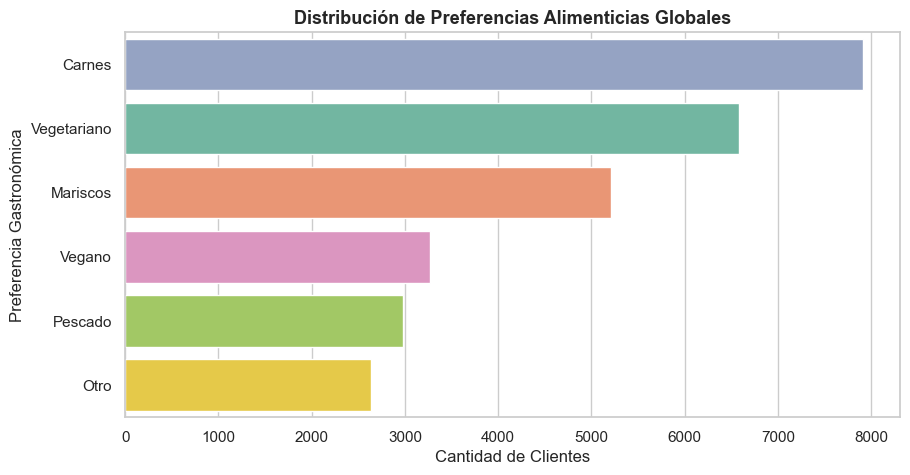


 🏆 PERFIL: CLIENTES DE MAYOR GASTO (Top 10%)
Gasto promedio mensual de este segmento: $677.82

Comidas favoritas de este segmento VIP:


preferencias_alimenticias
Carnes         763
Vegetariano    701
Mariscos       530
Name: count, dtype: int64


 💳 LÍDER EN FIDELIZACIÓN (Membresías Premium)
La ciudad con más membresías pagas es: Chicago
Total de suscripciones en esa ciudad: 2215


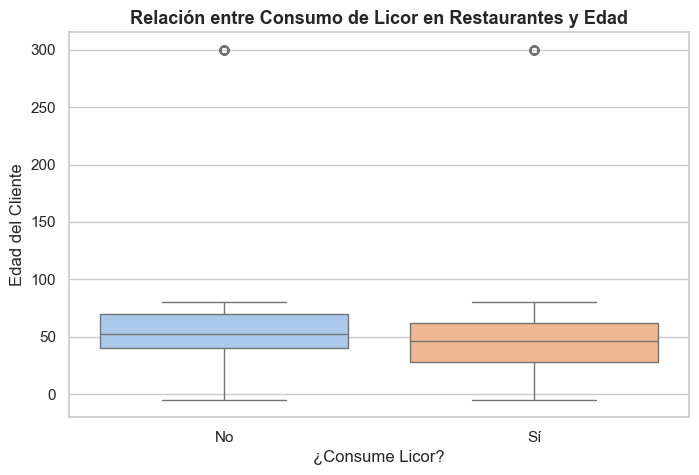

In [11]:
# --- PI 4: PERFILADO Y PREFERENCIAS ---

# 1. Gráfico: Preferencias alimenticias en todas las ciudades
plt.figure(figsize=(10, 5))
sns.countplot(data=df_clientes, y='preferencias_alimenticias', 
              order=df_clientes['preferencias_alimenticias'].value_counts().index, 
              palette='Set2', hue='preferencias_alimenticias', legend=False)
plt.title('Distribución de Preferencias Alimenticias Globales', fontweight='bold', fontsize=13)
plt.xlabel('Cantidad de Clientes')
plt.ylabel('Preferencia Gastronómica')
plt.show()

# 2. Listado: Perfilar clientes de mayor gasto (El Top 10%)
# Calculamos el corte del 10% que más gasta
umbral_alto_gasto = df_clientes['gasto_mensual'].quantile(0.90)
clientes_top = df_clientes[df_clientes['gasto_mensual'] >= umbral_alto_gasto]

print("\n" + "="*50)
print(" 🏆 PERFIL: CLIENTES DE MAYOR GASTO (Top 10%)")
print("="*50)
print(f"Gasto promedio mensual de este segmento: ${clientes_top['gasto_mensual'].mean():.2f}")
print("\nComidas favoritas de este segmento VIP:")
display(clientes_top['preferencias_alimenticias'].value_counts().head(3))

# 3. Dato: Ciudad con más membresías pagadas
# Filtramos solo los que dijeron que 'Sí' tienen membresía
df_membresias = df_clientes[df_clientes['membresia_premium'] == 'Sí']
ciudades_membresia = df_membresias['ciudad_residencia'].value_counts()

print("\n" + "="*50)
print(" 💳 LÍDER EN FIDELIZACIÓN (Membresías Premium)")
print("="*50)
print(f"La ciudad con más membresías pagas es: {ciudades_membresia.index[0]}")
print(f"Total de suscripciones en esa ciudad: {ciudades_membresia.iloc[0]}")

# 4. Gráfico: Consumo de alcohol vs Edad
plt.figure(figsize=(8, 5))
# El boxplot (diagrama de caja) es el mejor gráfico estadístico para ver edades vs categorías
sns.boxplot(data=df_clientes, x='consume_licor', y='edad', 
            palette='pastel', hue='consume_licor', legend=False)
plt.title('Relación entre Consumo de Licor en Restaurantes y Edad', fontweight='bold', fontsize=13)
plt.xlabel('¿Consume Licor?')
plt.ylabel('Edad del Cliente')
plt.show()

COMPARATIVA ESPECÍFICA: CHICAGO VS. EL RESTO DE LAS CIUDADES

In [12]:
import pandas as pd

# 0. Recargamos la base de datos por las dudas (A prueba de balas)
df_clientes = pd.read_csv('base_datos_restaurantes_USA_v2.csv')
df_clientes['gasto_mensual'] = df_clientes['frecuencia_visita'] * df_clientes['promedio_gasto_comida']

# --- COMPARATIVA ESPECÍFICA: CHICAGO VS. EL RESTO DE LAS CIUDADES ---

# 1. Separamos la base de datos en dos grupos
df_chicago = df_clientes[df_clientes['ciudad_residencia'] == 'Chicago']
df_resto = df_clientes[df_clientes['ciudad_residencia'] != 'Chicago']

print("\n" + "="*50)
print(" 🏙️ ANÁLISIS COMPARATIVO: CHICAGO VS. RESTO DE USA")
print("="*50)

# 2. Sacamos las métricas de Chicago
print("--- MÉTRICAS DE CHICAGO ---")
print(f"Total de clientes: {len(df_chicago)}")
print(f"Gasto promedio mensual: ${df_chicago['gasto_mensual'].mean():.2f}")

comida_chicago = df_chicago['preferencias_alimenticias'].mode()
print(f"Comida favorita: {comida_chicago[0] if not comida_chicago.empty else 'N/A'}")
print(f"Porcentaje con Membresía: {(len(df_chicago[df_chicago['membresia_premium'] == 'Sí']) / len(df_chicago) * 100):.1f}%")

# 3. Sacamos las métricas del Resto de las ciudades
print("\n--- MÉTRICAS DEL RESTO DE LAS CIUDADES ---")
print(f"Total de clientes: {len(df_resto)}")
print(f"Gasto promedio mensual: ${df_resto['gasto_mensual'].mean():.2f}")

comida_resto = df_resto['preferencias_alimenticias'].mode()
print(f"Comida favorita: {comida_resto[0] if not comida_resto.empty else 'N/A'}")
print(f"Porcentaje con Membresía: {(len(df_resto[df_resto['membresia_premium'] == 'Sí']) / len(df_resto) * 100):.1f}%")


 🏙️ ANÁLISIS COMPARATIVO: CHICAGO VS. RESTO DE USA
--- MÉTRICAS DE CHICAGO ---
Total de clientes: 5384
Gasto promedio mensual: $128.24
Comida favorita: Carnes
Porcentaje con Membresía: 41.1%

--- MÉTRICAS DEL RESTO DE LAS CIUDADES ---
Total de clientes: 24616
Gasto promedio mensual: $168.56
Comida favorita: Carnes
Porcentaje con Membresía: 43.2%


5. Conclusiones del EDA y Recomendaciones Estratégicas
Tras finalizar la etapa de Análisis Exploratorio de Datos (EDA) sobre la base de 30.000 registros, hemos logrado aislar patrones de consumo que resultan vitales para la toma de decisiones de negocio. La integración de variables demográficas, financieras y de comportamiento arroja los siguientes insights:

Hallazgos Clave del Negocio:
Concentración del Core Business: El 61.2% de nuestra base de clientes se agrupa en los estratos socioeconómicos Medio y Alto. La correlación positiva entre ingresos mensuales y gasto demuestra que la tracción de facturación depende de la frecuencia de visitas de este sector.

Liderazgo Geográfico Dividido: Mientras que Miami es la ciudad con mayor ticket promedio de gasto mensual general, Chicago es el líder indiscutido en fidelización, acumulando 2.215 suscripciones a la Membresía Premium.

Perfil del Cliente VIP (Top 10%): El decil de mayor valor es extremadamente rentable, con un gasto promedio mensual de $677.82 por cliente. Sus preferencias gastronómicas están fuertemente marcadas por los locales de Carnes y opciones Vegetarianas, dejando a los mariscos en un tercer lugar.

Recomendaciones Accionables (Next Steps):
Estrategia Cruzada Chicago-Miami: Debemos analizar qué beneficios de membresía están funcionando tan bien en Chicago para replicarlos urgentemente en Miami. Si logramos que los clientes de alto gasto de Miami se suscriban al nivel de los de Chicago, el LTV (Life Time Value) de la empresa se disparará.

Optimización de Oferta Gastronómica: Enfocar la captación de nuevos restaurantes ("Partners") en aquellos que ofrezcan cortes de carne premium y menúes vegetarianos de alta gama, ya que son los rubros que atraen al 10% de los clientes que nos dejan casi $680 mensuales.

Campañas de Marketing Segmentadas: Redirigir la pauta publicitaria para evitar el gasto generalizado. Las campañas de conversión deben apuntar exclusivamente a usuarios de ingresos medios-altos, priorizando las franjas etarias que mostraron mayor afinidad al consumo de licor en el análisis de distribución.